# Which Spotify tracks will reach the Global Top 50?

IS 4487 Business Analytics · Spotify Chart Project

**Decision.** Spotify’s music editorial team could review five tracks each week for broader playlist placement. We test whether a model improves that shortlist over picking the five closest to the Top 50.

Spotify expanded its support for emerging artists with [Fresh Finds Forward](https://newsroom.spotify.com/2026-09-17/fresh-finds-forward/) in September 2026. This historical test examines an editorial decision later in a song’s trajectory, once it is already charting.

**Prediction.** After a weekly Global Top Songs chart is published, score each track at ranks 51–200. A prediction is a hit if the same recording reaches ranks 1–50 at least once in the following four weekly charts.

**Run this notebook.** Open it in Google Colab or Jupyter with pandas, NumPy, scikit-learn and Matplotlib installed. Run the cells in order. The data cell downloads a pinned archive of public charts (about 10 MB). The notebook uses the original chart exports and needs no account credentials.

The saved run used Python 3.12.13, pandas 3.1.1, numpy 2.5.5, scikit-learn 1.9.1, matplotlib 3.11.2.

## 1. Load historical chart exports

Each export is a snapshot of one chart week ending on a Thursday. Spotify applies eligibility rules to the stream counts shown in Charts. We use chart rank, chart streams and chart history. Track titles and artists are retained to identify picks.

- [Spotify Global Weekly chart](https://charts.spotify.com/charts/view/regional-global-weekly/latest)
- [Spotify’s chart methodology](https://support.spotify.com/us/artists/article/understanding-spotify-charts/)
- [Pinned mirror of Spotify’s weekly CSV exports](https://github.com/evadatadev/musiktrends-spotify/tree/63d0741445ed9b8f725ab5760ee5273f1140d30a/data/raw)

In [1]:
import io
import re
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ARCHIVE_REVISION = "63d0741445ed9b8f725ab5760ee5273f1140d30a"
ARCHIVE_URL = f"https://codeload.github.com/evadatadev/musiktrends-spotify/zip/{ARCHIVE_REVISION}"
CHART_EXPORT = re.compile(
    r"/data/raw/(?:weekly-top-songs-global-20\d{2}/)?"
    r"regional-global-weekly-(\d{4}-\d{2}-\d{2})(?:_origin)?\.csv$"
)
CHART_COLUMNS = ["uri", "track_name", "artist_names", "rank", "streams", "weeks_on_chart"]
TOP_RANK = 50
LAST_RANK = 200
FOLLOWUP_WEEKS = 4
PICKS_PER_WEEK = 5
ONE_WEEK = pd.Timedelta(weeks=1)
TEST_START = pd.Timestamp("2025-07-03")

with urlopen(ARCHIVE_URL, timeout=60) as response:
    archive_bytes = response.read()

weekly_exports = []
with ZipFile(io.BytesIO(archive_bytes)) as archive:
    for member in sorted(archive.namelist()):
        match = CHART_EXPORT.search(member)
        if match is None:
            continue
        with archive.open(member) as csv_file:
            weekly = pd.read_csv(csv_file, usecols=CHART_COLUMNS, encoding="utf-8-sig")
        weekly["week"] = pd.Timestamp(match.group(1))
        weekly_exports.append(weekly)

chart = pd.concat(weekly_exports, ignore_index=True)
chart["track_id"] = chart.pop("uri").str.removeprefix("spotify:track:")
chart = chart.sort_values(["week", "rank"], ignore_index=True)
display(chart[["week", "rank", "track_name", "artist_names", "streams"]].head(3))

,week,rank,track_name,artist_names,streams
0,2024-01-04,1,greedy,Tate McRae,33855816
1,2024-01-04,2,La Diabla,Xavi,30894083
2,2024-01-04,3,Lovin On Me,Jack Harlow,30778444


## 2. Check chart coverage

A missing song can count as a miss only when the future Top 50 is complete. Scoring also needs a complete current chart and a complete prior-week chart to measure momentum consistently. We apply both rules before splitting the data.

In [2]:
chart_weeks = pd.DatetimeIndex(chart["week"].unique())
expected_weeks = pd.date_range(chart_weeks.min(), chart_weeks.max(), freq="W-THU")
assert chart_weeks.equals(expected_weeks), "The archive has a missing or shifted chart week."
assert chart[CHART_COLUMNS[1:] + ["track_id", "week"]].notna().all().all()
assert chart["track_id"].str.fullmatch(r"[A-Za-z0-9]{22}").all()
assert chart["rank"].between(1, LAST_RANK).all()
assert chart["streams"].gt(0).all() and chart["weeks_on_chart"].ge(1).all()
assert not chart.duplicated(["week", "track_id"]).any(), "Duplicate track-week."
assert not chart.duplicated(["week", "rank"]).any(), "Duplicate rank within a week."
assert chart.groupby("week")["streams"].apply(lambda streams: streams.is_monotonic_decreasing).all()

ranks_by_week = chart.groupby("week")["rank"].agg(set)
all_ranks = set(range(1, LAST_RANK + 1))
top_ranks = set(range(1, TOP_RANK + 1))
complete_charts = ranks_by_week.map(lambda ranks: ranks == all_ranks)
assert ranks_by_week.map(top_ranks.issubset).all(), "A chart is missing a top-50 rank."

print(f"{len(chart):,} chart rows across {len(chart_weeks)} consecutive weeks")
print(f"{chart_weeks.min():%Y-%m-%d} through {chart_weeks.max():%Y-%m-%d}")
for week, ranks in ranks_by_week[~complete_charts].items():
    print(f"Incomplete chart {week:%Y-%m-%d}, missing ranks {sorted(all_ranks - ranks)}")
print("Every observed weekly Top 50 is complete.")

21,399 chart rows across 107 consecutive weeks
2024-01-04 through 2026-01-15
Incomplete chart 2025-11-13, missing ranks [74]
Every observed weekly Top 50 is complete.


## 3. Build predictors and the four-week outcome

Compare each candidate with its own rank and stream count exactly one week earlier. Positive changes mean the track moved up or gained streams. For a track outside the prior Top 200, mark its prior appearance as false and fill its undefined changes with zero. Use the current week’s rank-50 stream count to measure how close each candidate is to the cutoff.

Look for the candidate’s track ID in the Top 50 exactly one, two, three or four weeks later. A track can leave the chart and return during that window. Keep dates with four full weeks of follow-up.

In [3]:
prior = chart[["week", "track_id", "rank", "streams"]].rename(
    columns={"rank": "prior_rank", "streams": "prior_streams"}
)
prior["week"] += ONE_WEEK
rank_50_streams = chart.loc[chart["rank"].eq(TOP_RANK)].set_index("week")["streams"]

candidates = chart.loc[chart["rank"].gt(TOP_RANK)].merge(
    prior, on=["week", "track_id"], how="left", validate="one_to_one"
)
candidates = candidates.loc[
    candidates["week"].map(complete_charts).fillna(False)
    & (candidates["week"] - ONE_WEEK).map(complete_charts).fillna(False)
    & candidates["week"].le(chart_weeks.max() - FOLLOWUP_WEEKS * ONE_WEEK)
].copy()
candidates["was_on_chart_last_week"] = candidates["prior_rank"].notna().astype(int)
candidates["rank_change"] = (candidates["prior_rank"] - candidates["rank"]).fillna(0)
candidates["log_streams"] = np.log(candidates["streams"])
candidates["log_stream_change"] = (
    candidates["log_streams"] - np.log(candidates["prior_streams"])
).fillna(0)
candidates["log_streams_vs_rank_50"] = (
    candidates["log_streams"] - np.log(candidates["week"].map(rank_50_streams))
)
candidates["log_weeks_on_chart"] = np.log1p(candidates["weeks_on_chart"])

future_top_50 = pd.MultiIndex.from_frame(
    chart.loc[chart["rank"].le(TOP_RANK), ["week", "track_id"]]
)
outcomes = []
for weeks_ahead in range(1, FOLLOWUP_WEEKS + 1):
    future_keys = pd.MultiIndex.from_arrays(
        [candidates["week"] + weeks_ahead * ONE_WEEK, candidates["track_id"]]
    )
    outcomes.append(future_keys.isin(future_top_50))
candidates["reached_top_50"] = np.logical_or.reduce(outcomes).astype(int)

FEATURES = [
    "rank", "log_streams", "log_streams_vs_rank_50", "log_weeks_on_chart",
    "was_on_chart_last_week", "rank_change", "log_stream_change",
]
assert np.isfinite(candidates[FEATURES].to_numpy()).all()
assert candidates.groupby("week").size().eq(LAST_RANK - TOP_RANK).all()
print(f"{len(candidates):,} eligible track-week examples before the time split")

15,000 eligible track-week examples before the time split


## 4. Train on earlier weeks and test on later weeks

Train both models on weeks whose four-week outcomes were fully known before July 3, 2025. Leave a four-week gap between the last training week and the first test week. The test simulates a fixed model scoring later charts as each becomes available. A track may appear in several weeks, matching the weekly editorial decision.

In [4]:
label_end = candidates["week"] + FOLLOWUP_WEEKS * ONE_WEEK
train = candidates.loc[label_end.lt(TEST_START)].copy()
test = candidates.loc[candidates["week"].ge(TEST_START)].copy()

assert train["week"].max() + FOLLOWUP_WEEKS * ONE_WEEK < test["week"].min()
assert train["reached_top_50"].nunique() == test["reached_top_50"].nunique() == 2
split_rows = []
for name, split in {"Training": train, "Test": test}.items():
    split_rows.append({
        "Sample": name,
        "First week": split["week"].min().date(),
        "Last week": split["week"].max().date(),
        "Weeks": split["week"].nunique(),
        "Track-week rows": len(split),
        "Reached Top 50": split["reached_top_50"].sum(),
        "Positive rate": split["reached_top_50"].mean(),
    })
split_summary = pd.DataFrame(split_rows).set_index("Sample")
split_summary["Positive rate"] = split_summary["Positive rate"].map("{:.1%}".format)
display(split_summary)
print(f"Gap weeks excluded before testing: {len(candidates) - len(train) - len(test):,} track-week rows")

,First week,Last week,Weeks,Track-week rows,Reached Top 50,Positive rate
Sample,,,,,,
Training,2024-01-11,2025-05-29,73,10950,716,6.5%
Test,2025-07-03,2025-12-18,23,3450,282,8.2%


Gap weeks excluded before testing: 600 track-week rows


## 5. Fit two models and score the weekly shortlist

- **Current rank** is the operational baseline. Pick ranks 51 through 55 each week.
- **Logistic regression** estimates the chance of a hit from the chart signals. Standardization is fit on the training data.
- **Random forest** combines decision trees. Cap tree depth and set a minimum leaf size to limit overfitting. Use a fixed random seed. Both models use fixed settings for the comparison.

**Precision at five** is the fraction of the five weekly picks that hit. It measures the editorial review workload directly. **Average precision** evaluates the full ranking of test rows, with an emphasis on how well methods surface hits when they are relatively rare.

In [5]:
models = {
    "Logistic regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, random_state=4487)
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=20, random_state=4487, n_jobs=-1
    ),
}
scores = {"Current rank": -test["rank"].to_numpy()}
for name, model in models.items():
    model.fit(train[FEATURES], train["reached_top_50"])
    scores[name] = model.predict_proba(test[FEATURES])[:, 1]

shortlist_tables = []
summary_rows = []
for name, score in scores.items():
    ranked = test.assign(method=name, score=score).sort_values(
        ["week", "score", "rank"], ascending=[True, False, True]
    )
    picks = ranked.groupby("week", sort=False).head(PICKS_PER_WEEK)
    assert picks.groupby("week").size().eq(PICKS_PER_WEEK).all()
    shortlist_tables.append(picks)
    summary_rows.append({
        "Method": name,
        "Correct picks": int(picks["reached_top_50"].sum()),
        "Total picks": len(picks),
        "Precision at 5": picks["reached_top_50"].mean(),
        "Average precision": average_precision_score(test["reached_top_50"], score),
    })

shortlists = pd.concat(shortlist_tables, ignore_index=True)
results = pd.DataFrame(summary_rows).set_index("Method")
display(results.assign(**{
    "Precision at 5": results["Precision at 5"].map("{:.1%}".format),
    "Average precision": results["Average precision"].round(3),
}))
print(f"Positive rate across all test candidates: {test['reached_top_50'].mean():.1%}")

,Correct picks,Total picks,Precision at 5,Average precision
Method,,,,
Current rank,55,115,47.8%,0.313
Logistic regression,55,115,47.8%,0.425
Random forest,57,115,49.6%,0.427


Positive rate across all test candidates: 8.2%


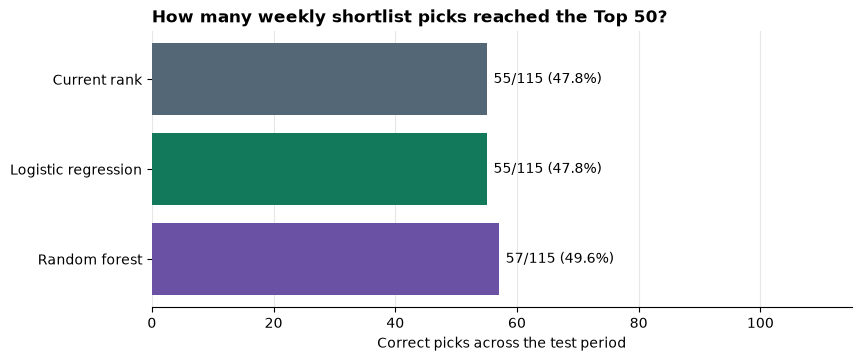

In [6]:
palette = {"Current rank": "#536777", "Logistic regression": "#13795b", "Random forest": "#6b51a3"}
fig, ax = plt.subplots(figsize=(8.5, 3.5), layout="constrained")
bars = ax.barh(results.index, results["Correct picks"], color=[palette[name] for name in results.index])
total_picks = int(results["Total picks"].iloc[0])
labels = [f"{int(row['Correct picks'])}/{total_picks} ({row['Precision at 5']:.1%})" for _, row in results.iterrows()]
ax.bar_label(bars, labels=labels, padding=5)
ax.set(xlabel="Correct picks across the test period", xlim=(0, total_picks))
ax.set_title("How many weekly shortlist picks reached the Top 50?", loc="left", fontweight="bold")
ax.invert_yaxis()
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="x", color="#e5e7eb")
plt.show()

## 6. Check how the comparison varies across weeks

Grouping by calendar month shows how dependent the aggregate comparison is on a few weeks. Each pick below is still scored with the same four-week outcome. December’s test period stops where the archive can supply four later charts.

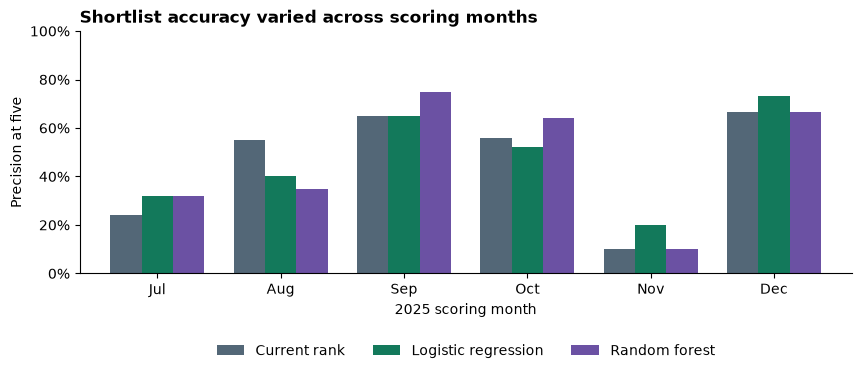

Logistic regression versus current rank: 5 better weeks, 13 ties, 5 worse weeks.
Random forest versus current rank: 7 better weeks, 12 ties, 4 worse weeks.


In [7]:
weekly_hits = (
    shortlists.groupby(["week", "method"])["reached_top_50"].sum().unstack()[results.index]
)
monthly_groups = weekly_hits.index.to_period("M")
monthly_hits = weekly_hits.groupby(monthly_groups).sum()
weeks_in_month = weekly_hits.groupby(monthly_groups).size()
monthly_precision = monthly_hits.div(weeks_in_month * PICKS_PER_WEEK, axis="index")

fig, ax = plt.subplots(figsize=(8.5, 3.6), layout="constrained")
monthly_precision.rename(index=lambda month: month.strftime("%b")).plot.bar(
    ax=ax, color=[palette[name] for name in results.index], rot=0, width=0.76
)
ax.set(xlabel="2025 scoring month", ylabel="Precision at five", ylim=(0, 1))
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
ax.set_title("Shortlist accuracy varied across scoring months", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.24))
plt.show()

baseline_hits = weekly_hits["Current rank"]
for name in models:
    delta = weekly_hits[name] - baseline_hits
    print(f"{name} versus current rank: {(delta > 0).sum()} better weeks, "
          f"{(delta == 0).sum()} ties, {(delta < 0).sum()} worse weeks.")

## 7. Translate the results into an editorial decision

Compare the strongest model with current rank using shortlist precision. The example shows what the model or baseline would have surfaced in a real week. Use these results to decide whether a more recent, prospective evaluation is worth running.

In [8]:
baseline_name = "Current rank"
preferred_method = results["Correct picks"].idxmax()
best_model = results.loc[list(models), "Precision at 5"].idxmax()
difference = results.loc[best_model, "Precision at 5"] - results.loc[baseline_name, "Precision at 5"]
hit_difference = results.loc[best_model, "Correct picks"] - results.loc[baseline_name, "Correct picks"]
print(f"Best model: {best_model} ({hit_difference:+d} correct picks, {difference * 100:+.1f} percentage points).")
if preferred_method == baseline_name:
    print("Recommendation: keep current rank as the shortlist rule and retest with newer charts.")
else:
    print(f"Recommendation: test {preferred_method} alongside current rank in a prospective editorial pilot.")

example_week = pd.Timestamp("2025-10-02")
example_picks = shortlists.loc[
    shortlists["week"].eq(example_week) & shortlists["method"].isin([baseline_name, best_model]),
    ["method", "rank", "track_name", "artist_names", "reached_top_50"],
].copy()
example_picks["reached_top_50"] = example_picks["reached_top_50"].map({1: "Yes", 0: "No"})
print(f"Example shortlist for chart week ending {example_week:%Y-%m-%d}")
display(example_picks.reset_index(drop=True))

Best model: Random forest (+2 correct picks, +1.7 percentage points).
Recommendation: test Random forest alongside current rank in a prospective editorial pilot.
Example shortlist for chart week ending 2025-10-02


,method,rank,track_name,artist_names,reached_top_50
0,Current rank,51,Every Breath You Take,The Police,Yes
1,Current rank,52,no tiene sentido,Beéle,No
2,Current rank,53,Sahiba,Aditya Rikhari,No
3,Current rank,54,TU VAS SIN (fav),Rels B,No
4,Current rank,55,Espresso,Sabrina Carpenter,No
5,Random forest,51,Every Breath You Take,The Police,Yes
6,Random forest,52,no tiene sentido,Beéle,No
7,Random forest,59,Nice To Each Other,Olivia Dean,No
8,Random forest,53,Sahiba,Aditya Rikhari,No
9,Random forest,83,So Easy (To Fall In Love),Olivia Dean,Yes


The forest found two more hits than current rank across 115 picks. Both models improved average precision across all candidates, while the five-pick comparison remained close. Keep current rank for routine shortlists and compare the forest alongside it on newer weeks before switching methods.

### Limits and follow-up

- The chart covers tracks already in the Global Top 200. An editorial team focused on earlier discovery would need signals from outside that chart.
- One incomplete candidate week and the following week were excluded from scoring because current and prior ranks were required. The partial week’s Top 50 was complete and usable for outcomes.
- Four-week outcome windows overlap, and tracks recur across weeks. The comparison describes one historical holdout. Use new chart weeks to check whether any improvement persists.
- The outcome measures chart momentum. To measure the effect of playlist placement, test the editorial workflow prospectively and track listener outcomes such as saves and repeat listening.